# 2 · Log analytics: find the incident before a customer does

**The question:** a web shop writes a log line for every request. Can we spot problems
automatically, quickly, without paging someone every hour for nothing?

**The test:** two simulated weeks of logs (1.2 million lines). **Week 1 is clean** and only used to
set alert thresholds. **Week 2 has 8 incidents injected at known times**: a big and a subtle
version of an error spike, a slow search page, a credential-stuffing attack (bots trying stolen
passwords) and an outage. The schedule is the answer key.

**Scoring:** an incident is *caught* if an alert fires between its start and 10 minutes after it ends.
Alerts that match no incident are *false alarms*: the thing that makes on-call people ignore alerts.

In [1]:
%matplotlib inline
import os, json
os.chdir('..')  # run from the project root so data/ and results/ resolve
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from oslab import plot, stack
plot.style()
pd.set_option('display.width', 160)
assert stack.is_up(), 'start the stack first: docker compose up -d'

from oslab import logs, logpipe, detect
incidents = detect.incidents_from_file()
pd.DataFrame([{'kind': i.kind, 'severity': i.severity, 'start (UTC)': i.start.strftime('%a %H:%M'), 'minutes': i.minutes} for i in incidents])

,kind,severity,start (UTC),minutes
0,cred_stuffing,subtle,Tue 22:40,30
1,error_spike,big,Fri 05:03,25
2,slow_search,subtle,Fri 12:15,60
3,outage,big,Fri 21:21,20
4,cred_stuffing,big,Sat 11:27,15
5,error_spike,subtle,Sat 20:22,60
6,slow_search,big,Sun 06:10,40
7,outage,subtle,Sun 13:30,30


## 1 · The pipeline

The generator writes JSON lines to `logs/shop.log`. **Fluent Bit**, a small log shipper that
normally runs next to every server, tails the file and sends batches to OpenSearch, one index per
day (`logs-shop-2026.10.05`, ...). Daily indices make deleting old data cheap: drop a whole index.

In [2]:
print(open('infra/fluent-bit/fluent-bit.conf').read().split('[OUTPUT]')[1])
print('documents in OpenSearch:', logpipe.count(), '   lines in the file:', sum(1 for _ in open('logs/shop.log')))


    Name                opensearch
    Match               *
    Host                opensearch
    Port                9200
    Logstash_Format     On
    Logstash_Prefix     logs-shop
    Logstash_DateFormat %Y.%m.%d
    Suppress_Type_Name  On
    # Hash of the record as the doc id: replaying the file can't create duplicates.
    Generate_ID         On
    Trace_Error         On
    Buffer_Size         False
    Retry_Limit         5

documents in OpenSearch: 1214202    lines in the file: 1214202


Every line arrived, once. `Generate_ID` makes each document's id a hash of its content, so
replaying the file can't create duplicates.

**Retention:** an *Index State Management* policy moves each daily index to read-only after 7 days
and deletes it after 30. Without one, a log cluster's disk and bill only ever grow.

In [3]:
p = stack.opensearch().transport.perform_request('GET', f'/_plugins/_ism/policies/{logpipe.POLICY}')['policy']
for s in p['states']:
    print(f"{s['name']:7s} actions={[k for a in s['actions'] for k in a if k != 'retry']} then -> {[(t['state_name'], t['conditions']) for t in s['transitions']]}")

hot     actions=[] then -> [('warm', {'min_index_age': '7d'})]
warm    actions=['read_only', 'force_merge'] then -> [('delete', {'min_index_age': '30d'})]
delete  actions=['delete'] then -> []


## 2 · Looking at week 2

Per-minute numbers come straight from OpenSearch *aggregations* (counts and sums per time bucket,
computed inside the cluster). Red bands are the injected incidents.

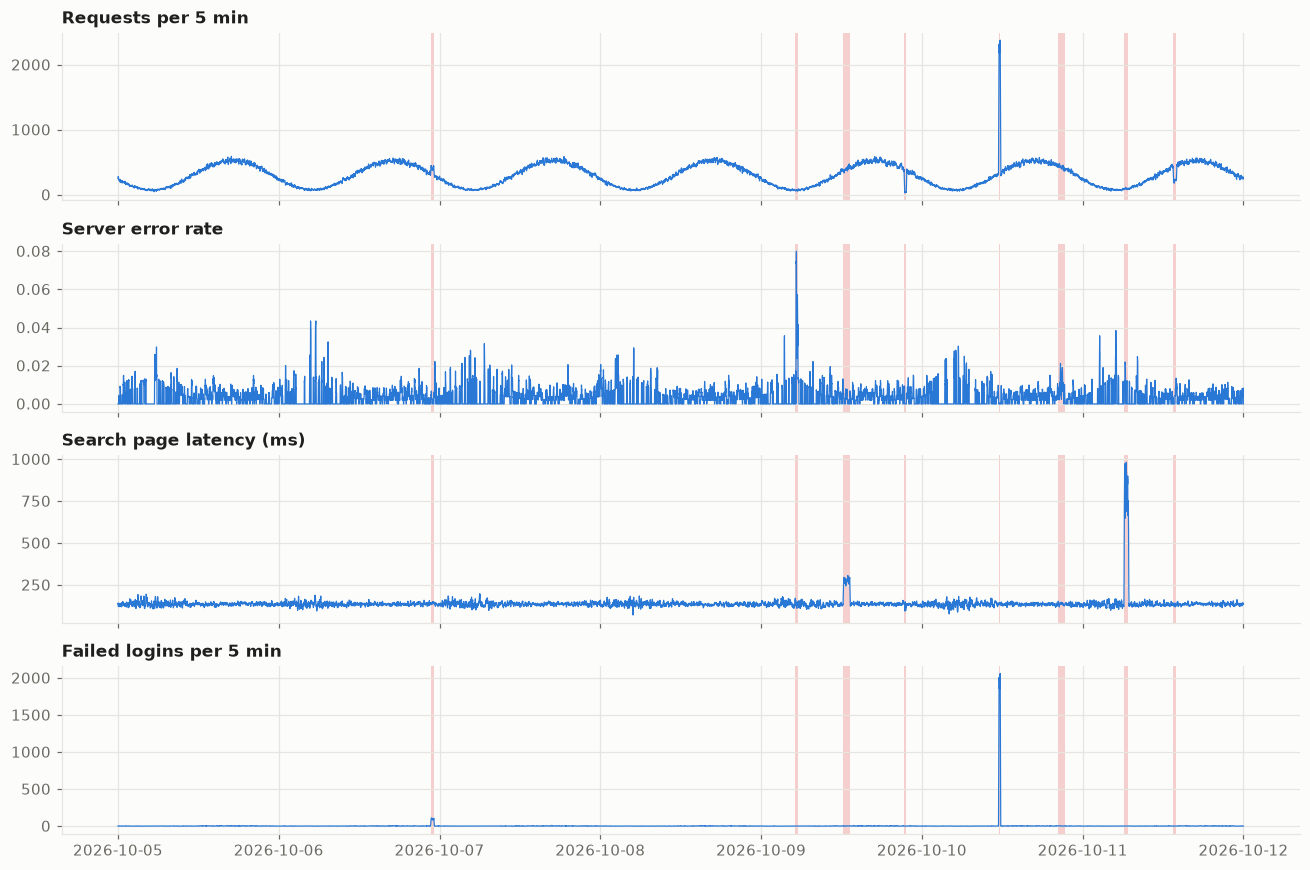

In [4]:
m = detect.minute_metrics()
f = detect.rolling_features(m)
w2 = f[f.index >= logs.TEST_START]
panels = [('requests', 'Requests per 5 min'), ('error_rate', 'Server error rate'),
          ('search_ms', 'Search page latency (ms)'), ('login_fail', 'Failed logins per 5 min')]
fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
for ax, (col, title) in zip(axes, panels):
    ax.plot(w2.index, w2[col], color=plot.SERIES[0], linewidth=0.8)
    for i in incidents:
        ax.axvspan(i.start, i.end, color=plot.INCIDENT, alpha=0.25, linewidth=0)
    ax.set_title(title)
plt.tight_layout()

Some incidents jump out (the big credential-stuffing attack). Others hide in the daily rhythm:
traffic swings 7x between 04:00 and 18:00, so a 50% drop at midday is still more traffic than a
normal night.

## 3 · Detector A: threshold rules

What most teams start with, and what an OpenSearch *Alerting monitor* checks every minute: a
number over the last 5 minutes crosses a line. Each line is set from the clean week only:
"the worst 5 minutes of a normal week, plus 10%". So by construction, week 1 never fires.

In [5]:
th = detect.calibrate(f)
alerts = detect.rule_alerts(f, th)
print({k: round(v, 3) for k, v in th.items()})
detect.per_rule_table(alerts, incidents).astype(int)

{'error_rate_high': 0.05, 'login_fail_high': 11.0, 'search_slow': 227.011, 'traffic_low_static': 47.273, 'traffic_low_seasonal': 0.619}


,error_rate_high,login_fail_high,search_slow,traffic_low_static,traffic_low_seasonal
cred_stuffing (subtle),0,1,0,0,0
error_spike (big),1,0,0,0,0
slow_search (subtle),0,0,1,0,0
outage (big),0,0,0,1,1
cred_stuffing (big),0,1,0,0,0
error_spike (subtle),0,0,0,0,0
slow_search (big),0,0,1,0,0
outage (subtle),0,0,0,0,1
false alarms,0,0,0,0,0


In [6]:
per, s = detect.score(detect.all_rule_minutes(alerts), incidents)
print(s)

{'caught': 7, 'of': 8, 'caught_big': 4, 'caught_subtle': 3, 'median_minutes_to_detect': 2.0, 'false_alarms': 0}


**Rules catch 7 of 8 with zero false alarms.** Two lessons:

- **The fixed traffic floor misses the subtle outage.** Only the *seasonal* rule (traffic vs the
  normal amount *for that time of day*) catches it.
- **The subtle error spike is missed by every rule.** Checkout errors rose to 8%, but checkout is
  8% of traffic, so the *shop-wide* error rate barely moves. A rule per endpoint would catch it.

The error-rate rule also exists as a real Alerting monitor (created disabled: our logs are in the
past, and a live monitor only looks at the last 5 minutes before *now*):

In [7]:
mon = detect.error_rate_monitor(th['error_rate_high'])
print(json.dumps(mon['inputs'][0]['search']['query'], indent=1)[:400])
print('trigger:', mon['triggers'][0]['condition']['script']['source'])

{
 "size": 0,
 "query": {
  "range": {
   "@timestamp": {
    "gte": "{{period_end}}||-5m",
    "lte": "{{period_end}}"
   }
  }
 },
 "aggs": {
  "errors": {
   "sum": {
    "field": "is_5xx"
   }
  }
 }
}
trigger: def n = ctx.results[0].hits.total.value; return n > 0 && ctx.results[0].aggregations.errors.value / n > 0.05000


## 4 · Detector B: the Anomaly Detection plugin

OpenSearch's built-in anomaly detection uses **Random Cut Forest**, a model that learns what normal
looks like and scores how surprising each new point is (the *anomaly grade*, 0 to 1). We gave it one
model per endpoint, watching request count, errors, average latency and failed logins, and **never
told it what an incident looks like**. It ran over both weeks as a *historical analysis*, at
1-minute and 5-minute intervals.

In [8]:
curve = pd.read_csv('results/ad-threshold-curve.csv')
curve[curve.min_grade.isin([0, 0.4, 0.8])][['interval_min', 'min_grade', 'caught', 'caught_big', 'caught_subtle', 'false_alarms', 'clean_week_false_alarms']]

,interval_min,min_grade,caught,caught_big,caught_subtle,false_alarms,clean_week_false_alarms
0,1,0.0,8,4,4,168,220
2,1,0.4,6,3,3,90,113
4,1,0.8,6,3,3,65,73
7,5,0.0,6,3,3,36,18
9,5,0.4,6,3,3,16,7
11,5,0.8,6,3,3,10,5


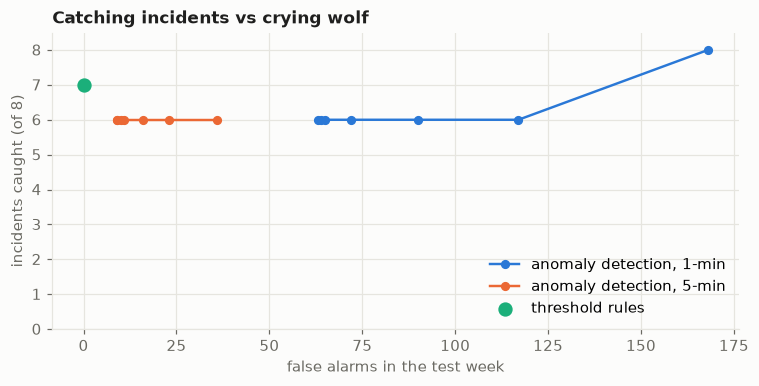

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.6))
for k, (iv, g) in enumerate(curve.groupby('interval_min')):
    ax.plot(g.false_alarms, g.caught, marker='o', markersize=5, color=plot.SERIES[k], label=f'anomaly detection, {iv}-min')
ax.scatter([s['false_alarms']], [s['caught']], s=70, color=plot.SERIES[2], zorder=3, label='threshold rules')
ax.set_xlabel('false alarms in the test week'); ax.set_ylabel('incidents caught (of 8)')
ax.set_ylim(0, 8.5); ax.legend(loc='lower right'); ax.set_title('Catching incidents vs crying wolf')
plt.tight_layout()

**Reading it:** at 1-minute resolution the model raises 65-170 false alarms a week. Per-endpoint
counts per minute are tiny (a handful of requests at night), so ordinary noise looks surprising.
At 5 minutes it is much quieter (about 10 a week at grade ≥ 0.8) but catches 6 of 8. Random Cut
Forest is random: re-running the same detector gives somewhat different results.

**Where the two disagree** (5-minute detector, grade ≥ 0.8):

In [10]:
ad = json.load(open('results/logs-ad-5m.json'))
rules = json.load(open('results/logs-rules.json'))
cmp = pd.DataFrame({'incident': [f"{i['kind']} ({i['severity']})" for i in rules['incidents']],
                    'rules': [i['caught'] for i in rules['incidents']],
                    'anomaly detection': [i['caught'] for i in ad['incidents']]})
cmp['either'] = cmp['rules'] | cmp['anomaly detection']
cmp

,incident,rules,anomaly detection,either
0,cred_stuffing (subtle),True,True,True
1,error_spike (big),True,True,True
2,slow_search (subtle),True,True,True
3,outage (big),True,True,True
4,cred_stuffing (big),True,False,True
5,error_spike (subtle),False,True,True
6,slow_search (big),True,True,True
7,outage (subtle),True,False,True


**The two are complementary.** Anomaly detection, modelling each endpoint separately, catches the
subtle checkout error spike that every shop-wide rule missed (late, after about 50 minutes). Rules
catch the known patterns fast and silently. Together they cover all 8.

**What a real team would do:** rules for the failure modes you know (errors, latency, traffic vs
the usual for this hour, login failures), each per endpoint; anomaly detection at a coarse interval
as a safety net for the ones you don't know, routed to a dashboard or a low-priority channel rather
than a pager.

## When *not* to use OpenSearch for this

- **Metrics only, no need to search raw lines:** a time-series database (Prometheus, CloudWatch
  metrics) is cheaper per data point.
- **Low volume:** CloudWatch Logs Insights or a managed log service avoids running a cluster.
- **Keep-forever archives:** keep raw logs in S3 and query them occasionally (Athena); keep only
  recent days in OpenSearch.

**Industry uses:** application troubleshooting, security monitoring (SIEM), audit trails, tracing
slow requests across services.